In [4]:
import torch
import numpy as np

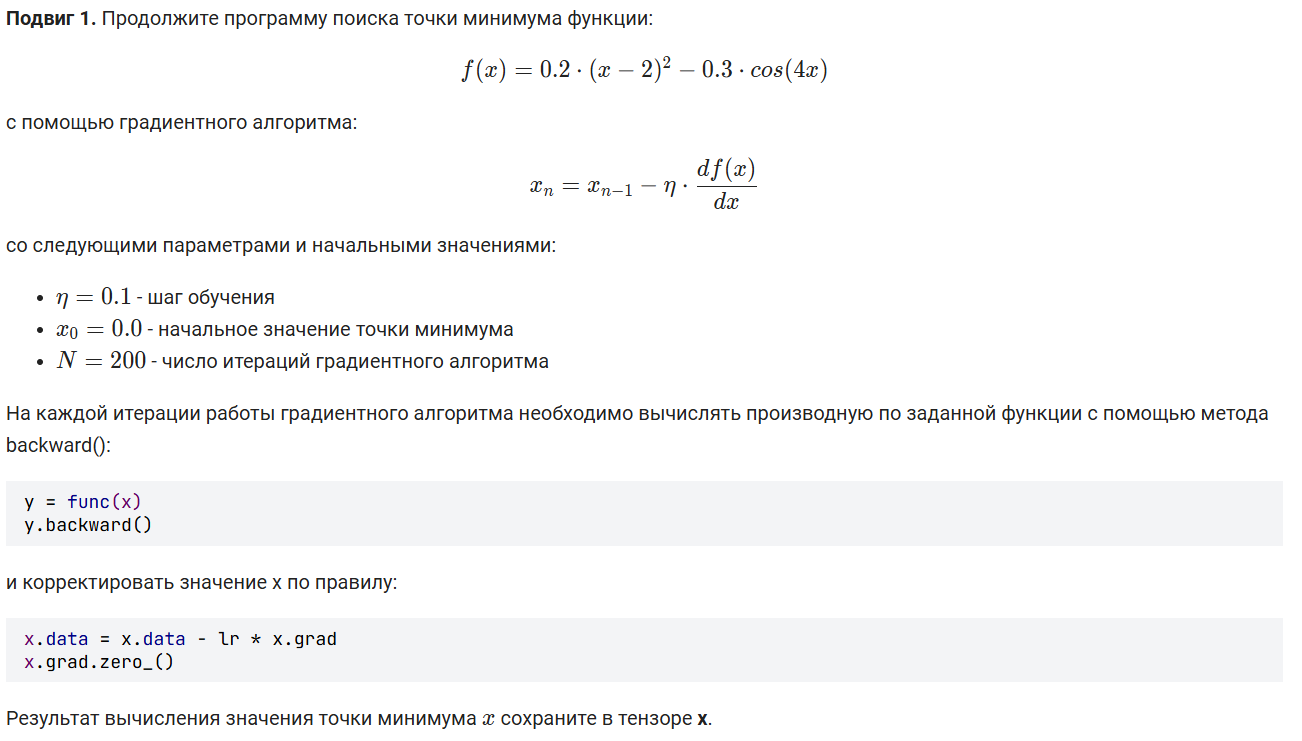

In [23]:
def func(x):
    return 0.2*(x-2)**2 - 0.3*torch.cos(4*x)

lr = 0.1
x = torch.tensor(0., requires_grad=True)
N = 200

for i in range(N):
    y = func(x)
    y.backward()
    x.data = x.data - lr*x.grad
    x.grad.zero_()

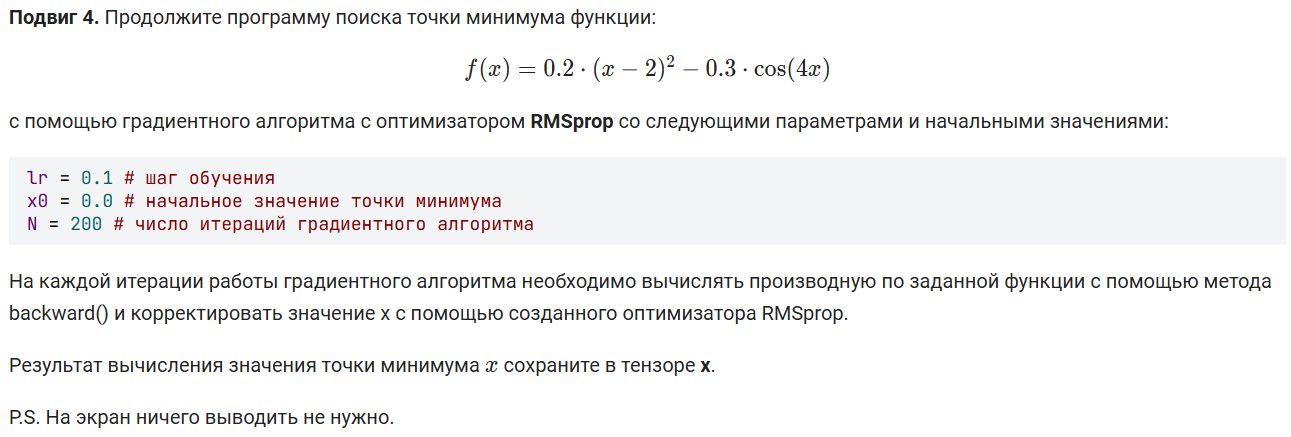

In [25]:
def func(x):
    return 0.2*(x-2)**2 - 0.3*torch.cos(4*x)

lr = 0.1
x = torch.tensor(0., requires_grad=True)
N = 200
opt = torch.optim.RMSprop(params=[x], lr=lr)

for i in range(N):
    y = func(x)
    y.backward()
    opt.step()
    x.grad.zero_()


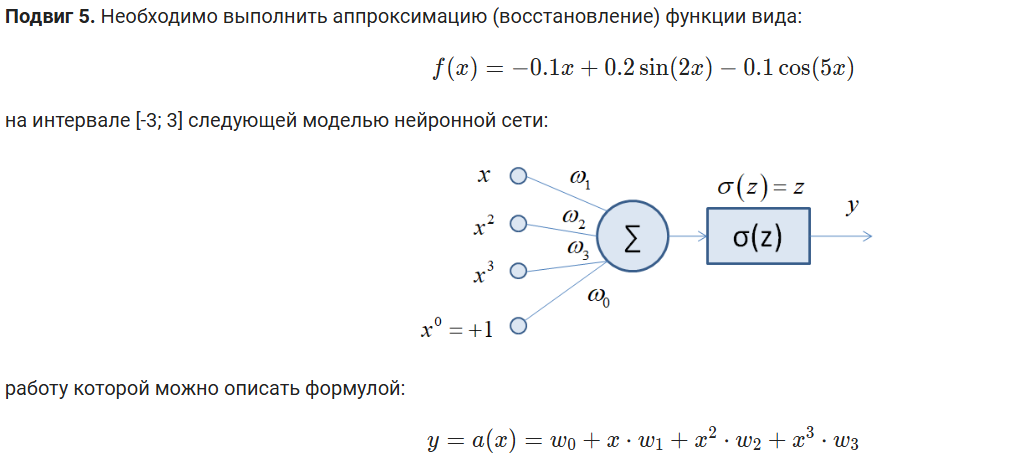

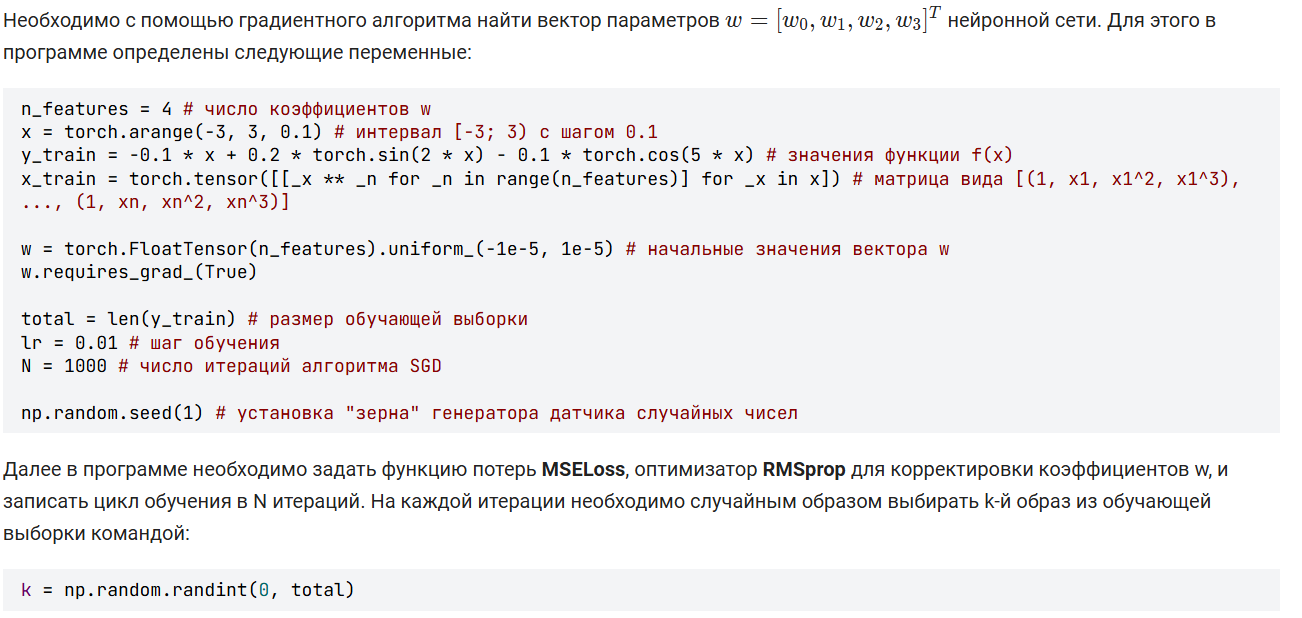

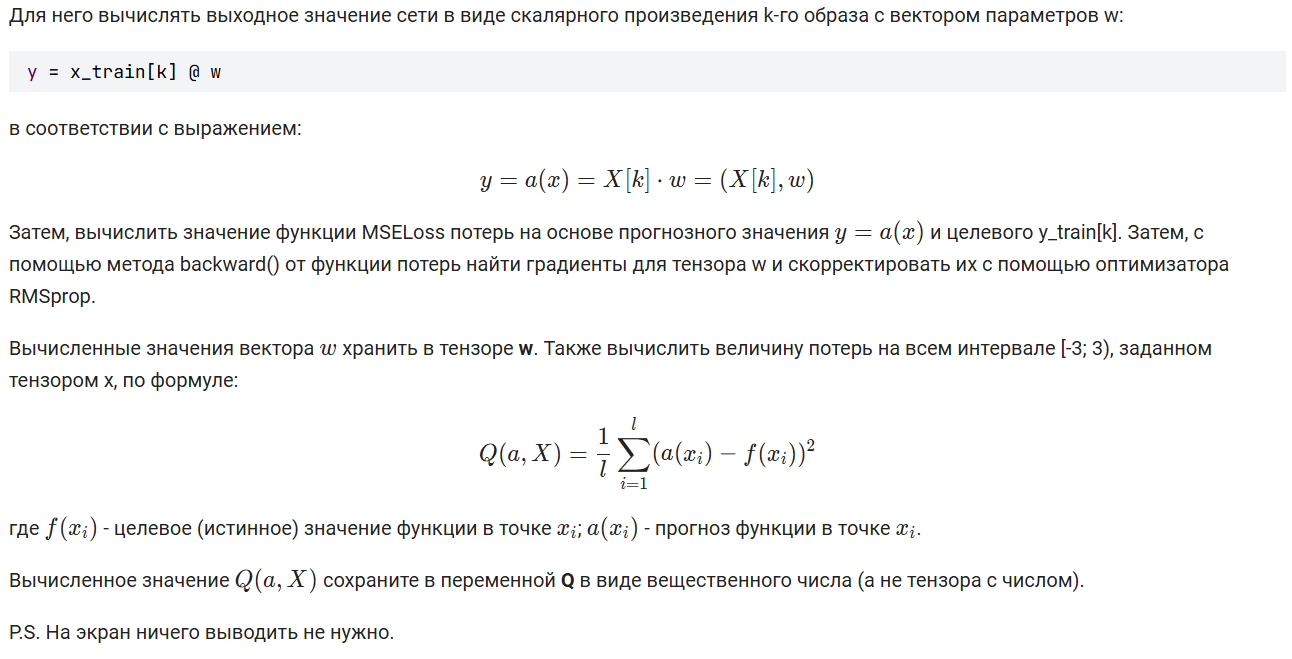

In [31]:
import numpy as np
import torch
import torch.optim as optim

n_features = 4 # число коэффициентов w
x = torch.arange(-3, 3, 0.1)
y_train = -0.1 * x + 0.2 * torch.sin(2 * x) - 0.1 * torch.cos(5 * x)
x_train = torch.tensor([[_x ** _n for _n in range(n_features)] for _x in x])

w = torch.FloatTensor(n_features).uniform_(-1e-5, 1e-5)
w.requires_grad_(True)

total = len(y_train)
lr = 0.01 # шаг обучения
N = 1000 # число итераций алгоритма SGD

np.random.seed(1) # установка "зерна" генератора датчика случайных чисел

loss_f = torch.nn.MSELoss()
opt = optim.RMSprop(params=[w], lr=lr)

for i in range(N):
    k = np.random.randint(0, total)
    y_pred = x_train @ w

    loss = loss_f(y_train[k], y_pred[k])
    loss.backward()
    opt.step()
    w.grad.zero_()


    Q = loss_f(y_train, x_train @ w).item()
    

Q

# здесь продолжайте программу

0.029087074100971222

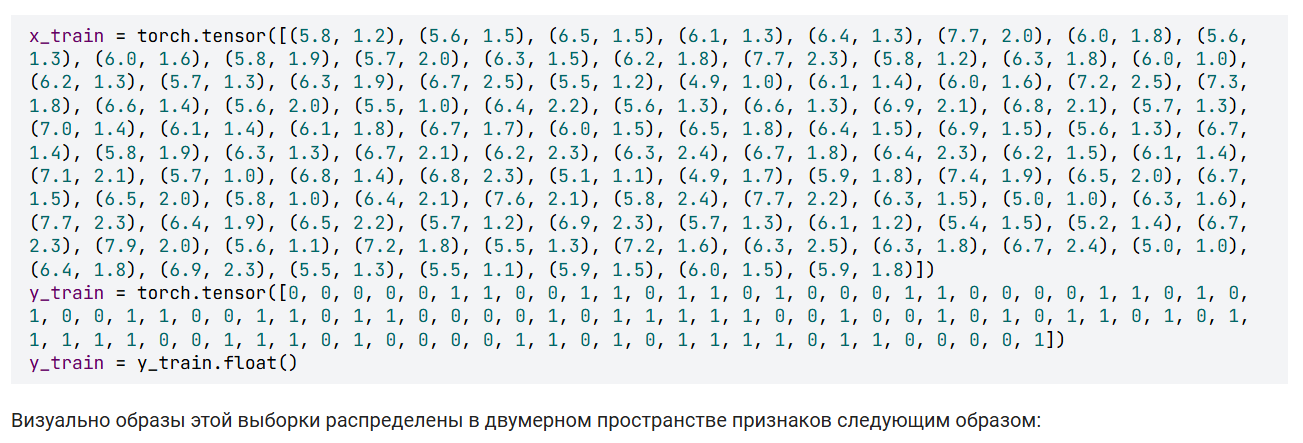

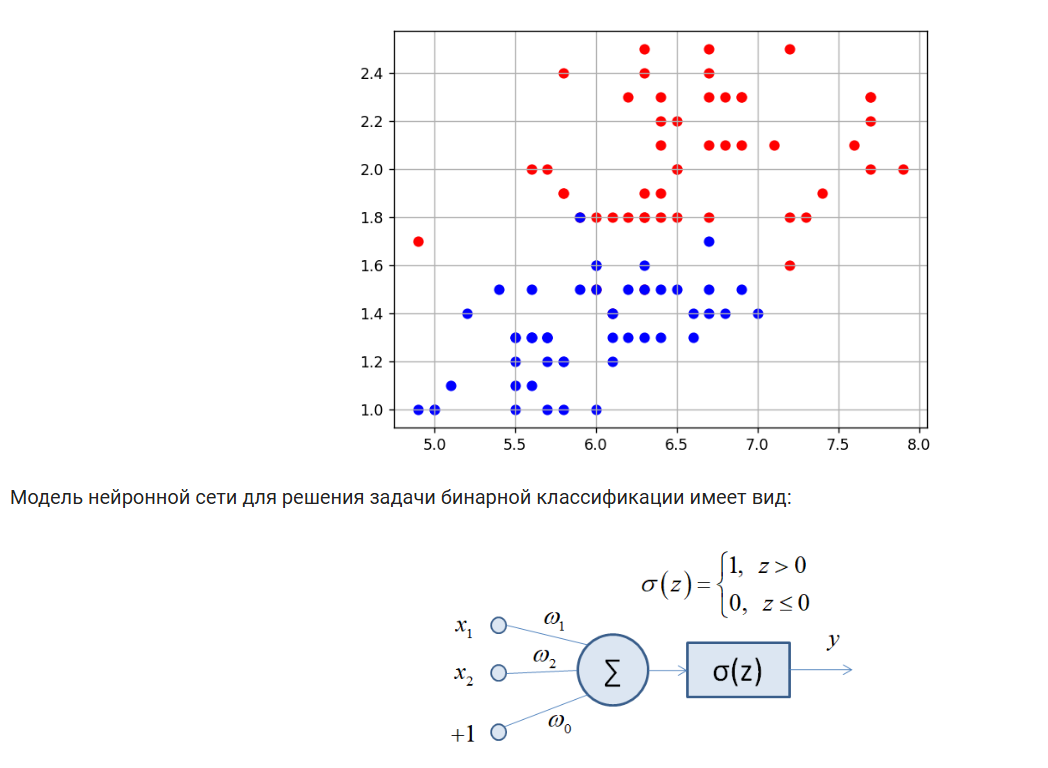

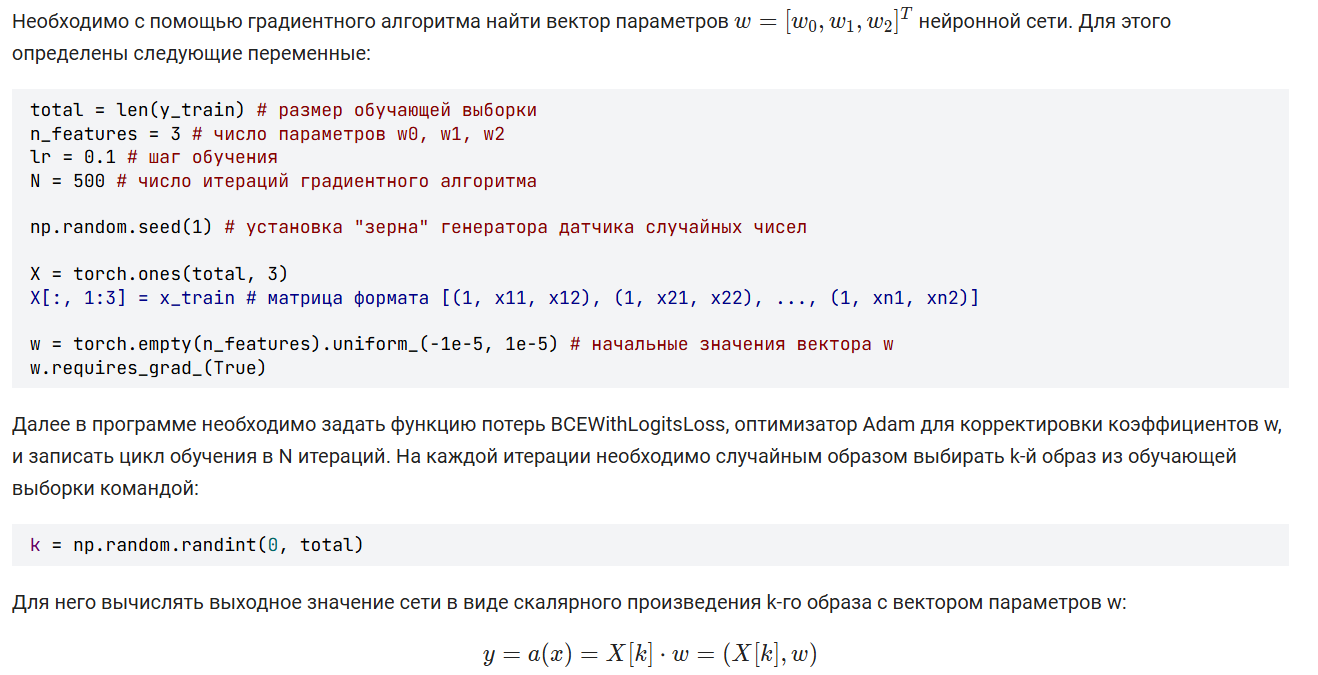

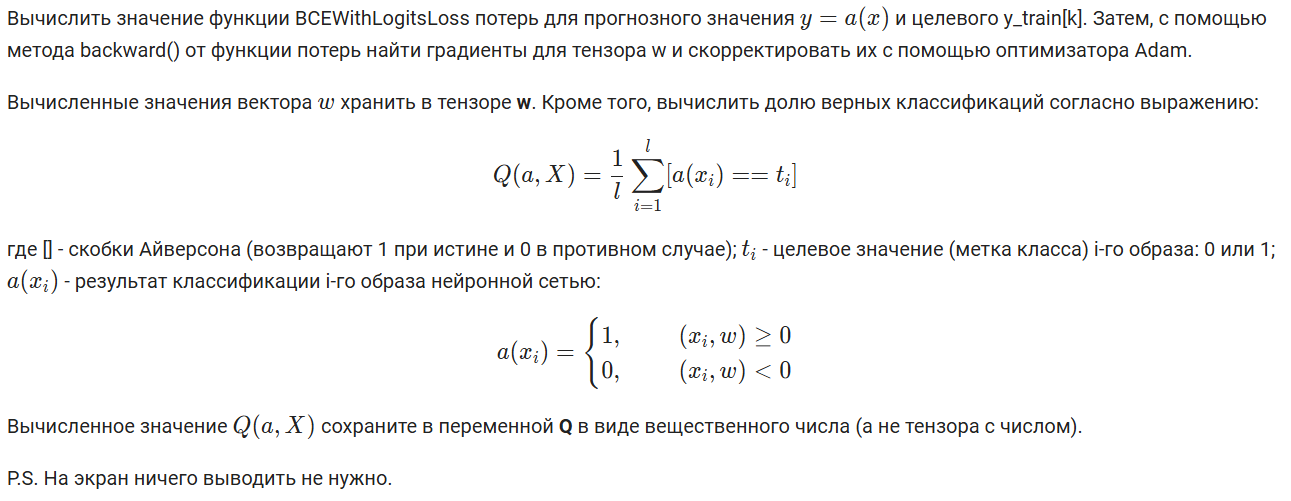

In [68]:
import numpy as np
import torch
import torch.optim as optim

x_train = torch.tensor([(5.8, 1.2), (5.6, 1.5), (6.5, 1.5), (6.1, 1.3), (6.4, 1.3), (7.7, 2.0), (6.0, 1.8), (5.6, 1.3), (6.0, 1.6), (5.8, 1.9), (5.7, 2.0), (6.3, 1.5), (6.2, 1.8), (7.7, 2.3), (5.8, 1.2), (6.3, 1.8), (6.0, 1.0), (6.2, 1.3), (5.7, 1.3), (6.3, 1.9), (6.7, 2.5), (5.5, 1.2), (4.9, 1.0), (6.1, 1.4), (6.0, 1.6), (7.2, 2.5), (7.3, 1.8), (6.6, 1.4), (5.6, 2.0), (5.5, 1.0), (6.4, 2.2), (5.6, 1.3), (6.6, 1.3), (6.9, 2.1), (6.8, 2.1), (5.7, 1.3), (7.0, 1.4), (6.1, 1.4), (6.1, 1.8), (6.7, 1.7), (6.0, 1.5), (6.5, 1.8), (6.4, 1.5), (6.9, 1.5), (5.6, 1.3), (6.7, 1.4), (5.8, 1.9), (6.3, 1.3), (6.7, 2.1), (6.2, 2.3), (6.3, 2.4), (6.7, 1.8), (6.4, 2.3), (6.2, 1.5), (6.1, 1.4), (7.1, 2.1), (5.7, 1.0), (6.8, 1.4), (6.8, 2.3), (5.1, 1.1), (4.9, 1.7), (5.9, 1.8), (7.4, 1.9), (6.5, 2.0), (6.7, 1.5), (6.5, 2.0), (5.8, 1.0), (6.4, 2.1), (7.6, 2.1), (5.8, 2.4), (7.7, 2.2), (6.3, 1.5), (5.0, 1.0), (6.3, 1.6), (7.7, 2.3), (6.4, 1.9), (6.5, 2.2), (5.7, 1.2), (6.9, 2.3), (5.7, 1.3), (6.1, 1.2), (5.4, 1.5), (5.2, 1.4), (6.7, 2.3), (7.9, 2.0), (5.6, 1.1), (7.2, 1.8), (5.5, 1.3), (7.2, 1.6), (6.3, 2.5), (6.3, 1.8), (6.7, 2.4), (5.0, 1.0), (6.4, 1.8), (6.9, 2.3), (5.5, 1.3), (5.5, 1.1), (5.9, 1.5), (6.0, 1.5), (5.9, 1.8)])
y_train = torch.tensor([0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1])
y_train = y_train.float()

total = len(y_train) # размер обучающей выборки
n_features = 3 # число параметров w0, w1, w2
lr = 0.1 # шаг обучения
N = 500 # число итераций градиентного алгоритма

np.random.seed(1) # установка "зерна" генератора датчика случайных чисел

X = torch.ones(total, 3)
X[:, 1:3] = x_train # матрица формата [(1, x11, x12), (1, x21, x22), ..., (1, xn1, xn2)]

w = torch.empty(n_features).uniform_(-1e-5, 1e-5) # начальные значения вектора w
w.requires_grad_(True)

# здесь продолжайте программу
loss_f = torch.nn.BCEWithLogitsLoss()
optim = torch.optim.Adam(params = [w], lr=lr)

for _ in range(N):
    k = np.random.randint(0, total)
    y_pred = X[k] @ w
    # loss = loss_f(y_train[k], y_pred)
    loss = loss_f(y_pred, y_train[k])
    loss.backward()
    optim.step()
    optim.zero_grad()

Q = torch.mean((torch.sign(X @ w) == (y_train * 2 - 1)).float())



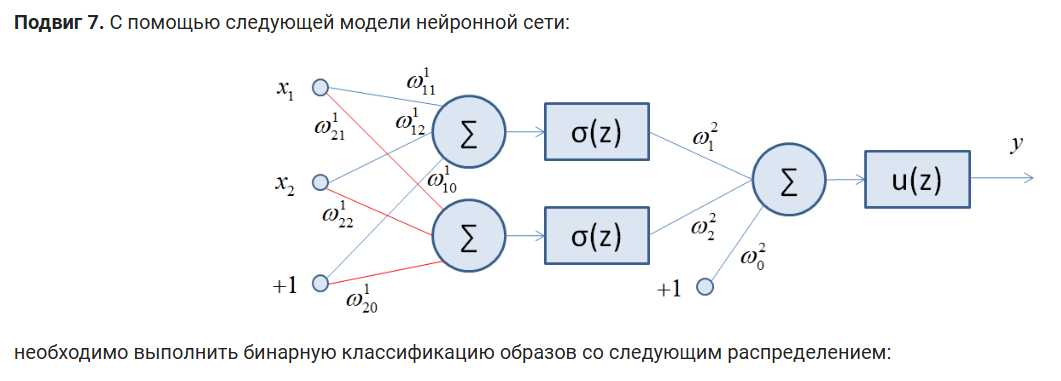

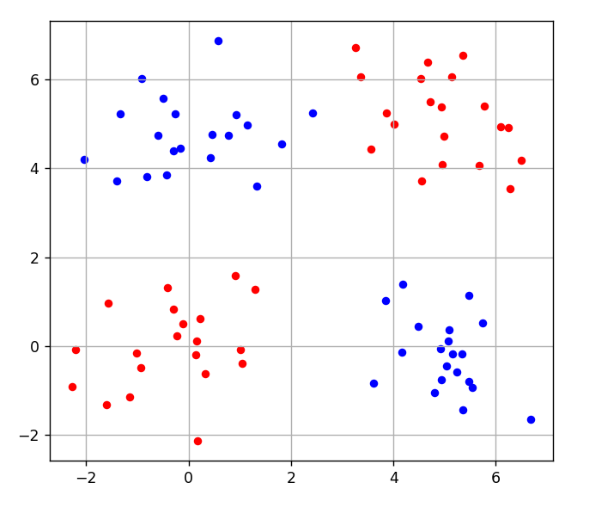

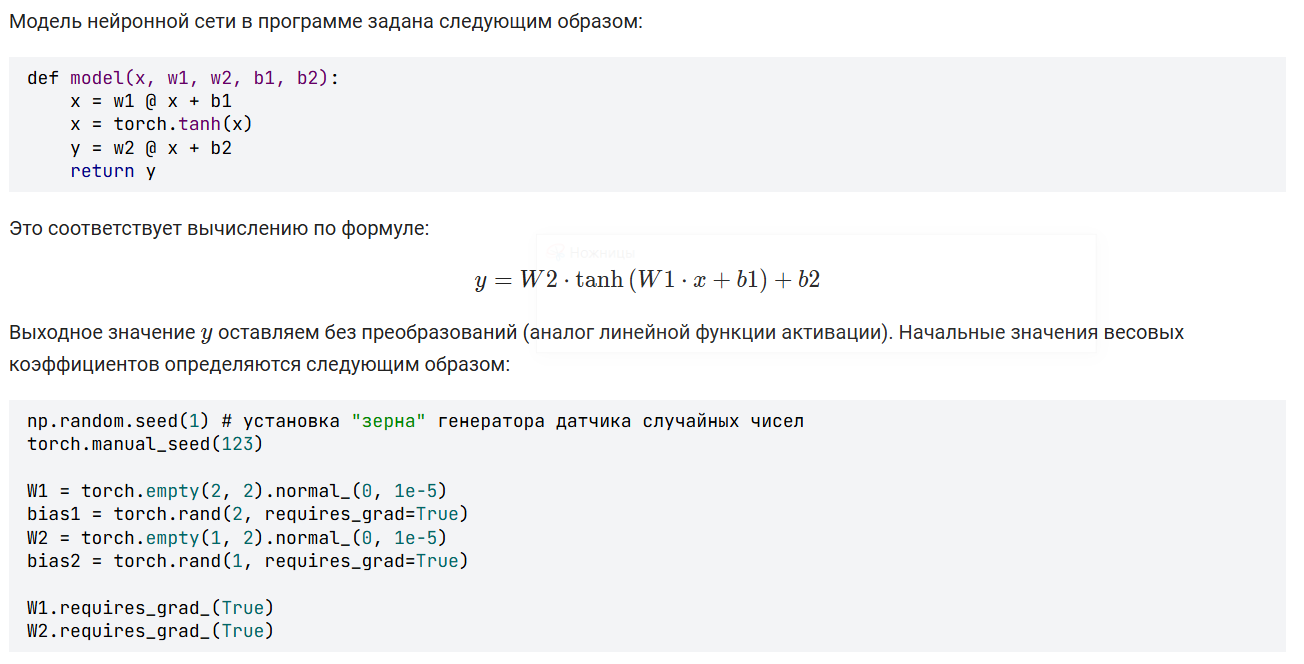

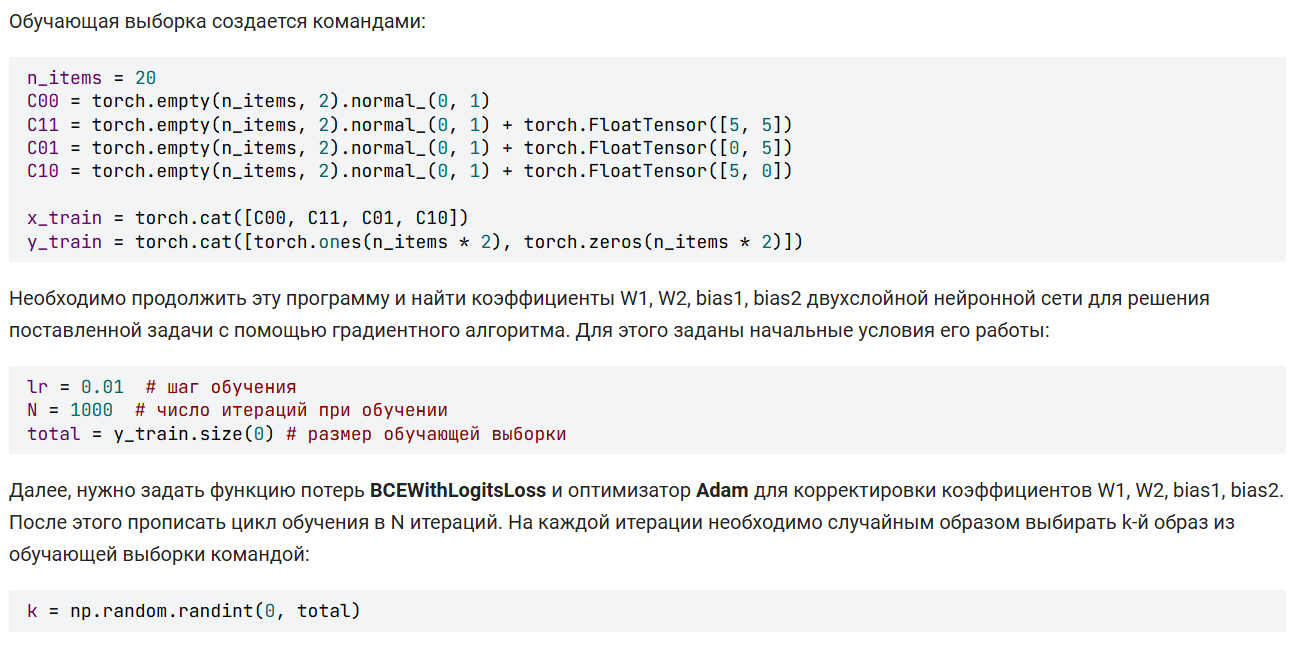

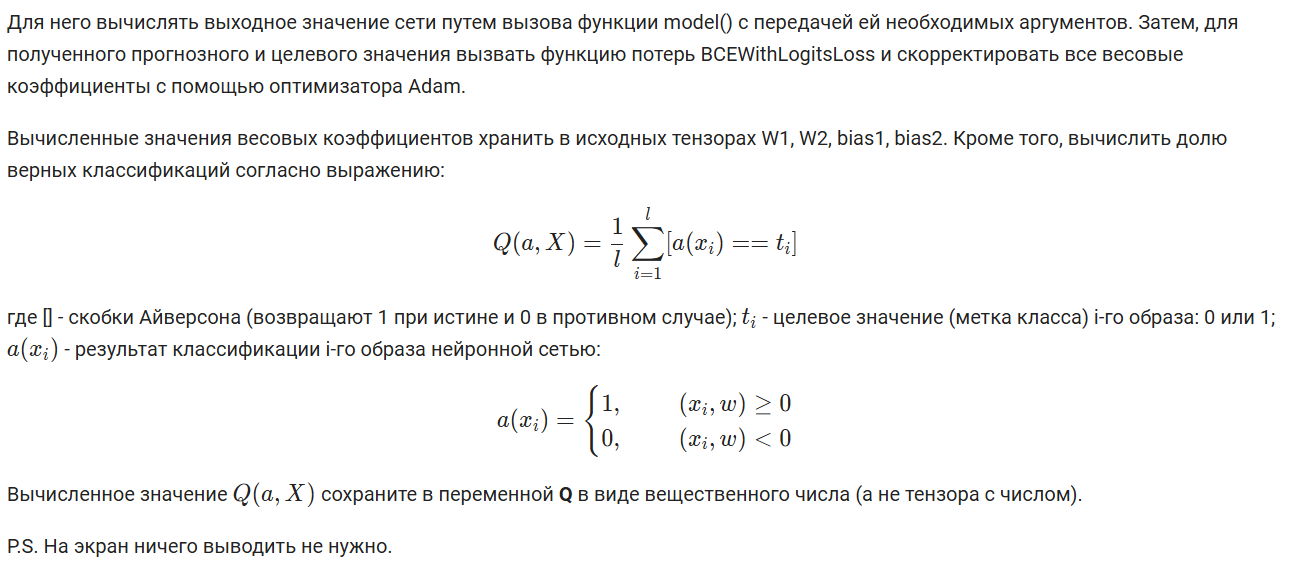

In [142]:
import numpy as np
import torch
import torch.optim as optim

def model(x, w1, w2, b1, b2):
    x = w1 @ x + b1
    x = torch.tanh(x)
    x = w2 @ x + b2
    return x

def model(x, w1, w2, b1, b2):
    x = x @ w1.permute(1, 0) + b1                 # [80x2] @ [2x2] = [80x2]           
    x = torch.tanh(x)
    x = x @ w2.permute(1, 0) + b2                 # [80x2] @ [2x1] = [80x1]
    return x


np.random.seed(1) # установка "зерна" генератора датчика случайных чисел
torch.manual_seed(123)

W1 = torch.empty(2, 2).normal_(0, 1e-5)
bias1 = torch.rand(2, requires_grad=True)
W2 = torch.empty(1, 2).normal_(0, 1e-5)
bias2 = torch.rand(1, requires_grad=True)

W1.requires_grad_(True)
W2.requires_grad_(True)

# обучающая выборка
n_items = 20
C00 = torch.empty(n_items, 2).normal_(0, 1)
C11 = torch.empty(n_items, 2).normal_(0, 1) + torch.FloatTensor([5, 5])
C01 = torch.empty(n_items, 2).normal_(0, 1) + torch.FloatTensor([0, 5])
C10 = torch.empty(n_items, 2).normal_(0, 1) + torch.FloatTensor([5, 0])

x_train = torch.cat([C00, C11, C01, C10])
y_train = torch.cat([torch.ones(n_items * 2), torch.zeros(n_items * 2)])

lr = 0.01  # шаг обучения
N = 1000  # число итераций при обучении
total = y_train.size(0) # размер обучающей выборки

# здесь продолжайте программу
loss_f = torch.nn.BCEWithLogitsLoss()
optim = torch.optim.Adam(params = [W1, W2, bias1, bias2], lr=lr)

for _ in range(N):
    k = np.random.randint(0, total)
    pred = model(x_train[k], W1, W2, bias1, bias2)
    loss = loss_f(pred, y_train[k].view(-1))
    optim.zero_grad()
    loss.backward()
    optim.step()

# Q = torch.mean((torch.sign(X @ w) == (y_train * 2 - 1)).float())
Q = torch.mean((torch.sign(model(x_train, W1, W2, bias1, bias2)) == (y_train * 2 - 1).unsqueeze(1)).float()).item()
Q

0.949999988079071

In [100]:
x_train.shape

torch.Size([80, 2])

In [108]:
W2.shape

torch.Size([1, 2])

In [135]:
model(x_train, W1, W2, bias1, bias2).shape

torch.Size([80, 1])

In [139]:
(y_train * 2 - 1).unsqueeze(1).shape

torch.Size([80, 1])

In [140]:
(torch.sign(model(x_train, W1, W2, bias1, bias2)) == (y_train * 2 - 1).unsqueeze(1))

tensor([[ True],
        [ True],
        [False],
        [False],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [False],
        [ True],
        [ True],
        [False],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True],
        [ True

In [128]:
Q

0.5